# 🛡️ AI ScamGuard — NLP & Machine Learning

This notebook contains the Data Science, NLP and Machine Learning part of the AI ScamGuard project.

**Pipeline:** Dataset → EDA → Text Preprocessing → TF-IDF → ML Models → Evaluation → Best Model → Save Model

The saved model will later be loaded by the Streamlit `app.py`.


## 1. Import Required Libraries

- Pandas / NumPy — data handling
- Matplotlib / Seaborn — visualization
- Scikit-learn — NLP, ML and evaluation
- Joblib — save the trained model


In [7]:
import os
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)

print("Libraries imported successfully.")


Libraries imported successfully.


## 2. Load the Dataset

Expected file:

`../data/messages.csv`

Required columns:
- `message`
- `label` (`scam` or `safe`)


In [8]:

df = pd.read_csv("D:\ML VT\AI Scam guard project\data\messages.csv")

print("Dataset loaded successfully.")
print("Shape:", df.shape)
df.head()


Dataset loaded successfully.
Shape: (400, 2)


,message,label
0,Reminder: Your payment receipt is available in your account dashboard.,safe
1,IMPORTANT: Your credit card is blocked. Share CVV and OTP for instant activation.,scam
2,Emergency: your account has been compromised. Tell us the OTP to secure it.,scam
3,FINAL WARNING: Your account will be closed in 10 minutes unless you verify your details. Do not ignore this message.,scam
4,Reminder: Please find the assignment guidelines attached for tomorrow's class.,safe


## 3. Understand the Dataset

In [9]:
print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nLabel distribution:")
print(df["label"].value_counts())


Dataset shape: (400, 2)

Columns:
['message', 'label']

Data types:
message    str
label      str
dtype: object

Missing values:
message    0
label      0
dtype: int64

Duplicate rows: 247

Label distribution:
label
safe    200
scam    200
Name: count, dtype: int64


In [10]:
df.describe(include="all").T


,count,unique,top,freq
message,400,153,Emergency: your account has been compromised. Tell us the OTP to secure it.,6
label,400,2,safe,200


## 4. Data Cleaning

In [11]:
df = df.dropna(subset=["message", "label"]).copy()
df["message"] = df["message"].astype(str).str.strip()
df["label"] = df["label"].astype(str).str.lower().str.strip()
df = df[df["label"].isin(["scam", "safe"])]

before = len(df)
df = df.drop_duplicates(subset=["message"]).reset_index(drop=True)

print("Rows after cleaning:", len(df))
print("Duplicates removed:", before - len(df))
print(df["label"].value_counts())


Rows after cleaning: 153
Duplicates removed: 247
label
safe    83
scam    70
Name: count, dtype: int64


## 5. Exploratory Data Analysis (EDA)

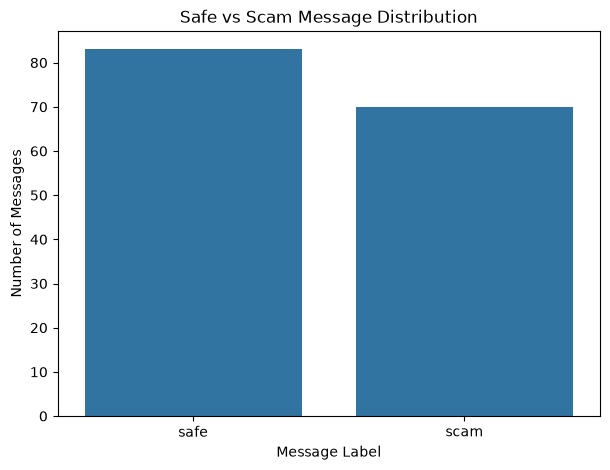

In [12]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="label")
plt.title("Safe vs Scam Message Distribution")
plt.xlabel("Message Label")
plt.ylabel("Number of Messages")
plt.show()


In [13]:
df["message_length"] = df["message"].str.len()
df["word_count"] = df["message"].str.split().str.len()

display(df.groupby("label")[["message_length", "word_count"]].mean().round(2))


,message_length,word_count
label,,
safe,75.75,12.39
scam,90.47,14.61


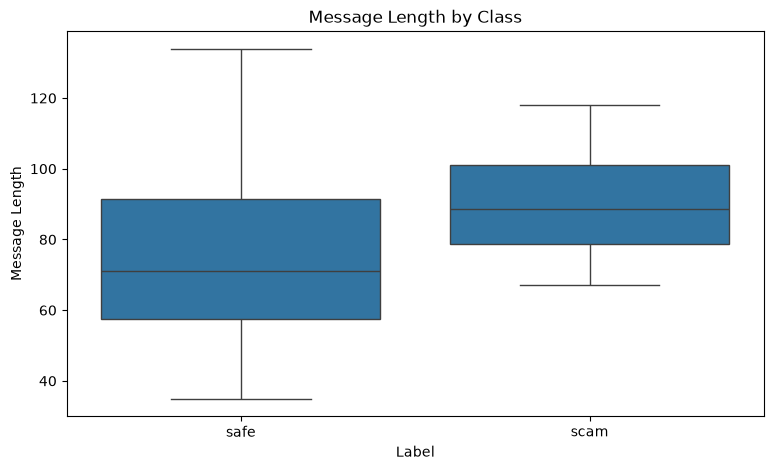

In [14]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="label", y="message_length")
plt.title("Message Length by Class")
plt.xlabel("Label")
plt.ylabel("Message Length")
plt.show()


## 6. NLP Text Preprocessing

The baseline NLP pipeline cleans the text and then uses **TF-IDF with unigrams and bigrams** to convert messages into numerical features.


In [15]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\.\S+", " URL ", text)
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean_message"] = df["message"].apply(clean_text)
df[["message", "clean_message", "label"]].head(10)


,message,clean_message,label
0,Reminder: Your payment receipt is available in your account dashboard.,reminder your payment receipt is available in your account dashboard,safe
1,IMPORTANT: Your credit card is blocked. Share CVV and OTP for instant activation.,important your credit card is blocked share cvv and otp for instant activation,scam
2,Emergency: your account has been compromised. Tell us the OTP to secure it.,emergency your account has been compromised tell us the otp to secure it,scam
3,FINAL WARNING: Your account will be closed in 10 minutes unless you verify your details. Do not ignore this message.,final warning your account will be closed in 10 minutes unless you verify your details do not ignore this message,scam
4,Reminder: Please find the assignment guidelines attached for tomorrow's class.,reminder please find the assignment guidelines attached for tomorrow s class,safe
5,The project review meeting has been moved to Monday. Thank you.,the project review meeting has been moved to monday thank you,safe
6,IMPORTANT: Security alert: suspicious activity detected. Confirm your password and verification code.,important security alert suspicious activity detected confirm your password and verification code,scam
7,Your KYC has expired. Verify your account now using the link below.,your kyc has expired verify your account now using the link below,scam
8,Reminder: Your salary slip is available in the employee portal.,reminder your salary slip is available in the employee portal,safe
9,Your package has been delivered successfully. Please check the official app for details.,your package has been delivered successfully please check the official app for details,safe


## 7. Train/Test Split

In [16]:
X = df["clean_message"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 122
Testing samples: 31


## 8. TF-IDF + Machine Learning Models

We compare:
1. Multinomial Naive Bayes
2. Logistic Regression
3. Linear SVM


In [17]:
models = {
    "Naive Bayes": Pipeline([
        ("tfidf", TfidfVectorizer(lowercase=True, ngram_range=(1, 2), sublinear_tf=True)),
        ("classifier", MultinomialNB())
    ]),
    "Logistic Regression": Pipeline([
        ("tfidf", TfidfVectorizer(lowercase=True, ngram_range=(1, 2), sublinear_tf=True)),
        ("classifier", LogisticRegression(max_iter=2000, class_weight="balanced"))
    ]),
    "SVM": Pipeline([
        ("tfidf", TfidfVectorizer(lowercase=True, ngram_range=(1, 2), sublinear_tf=True)),
        ("classifier", LinearSVC(class_weight="balanced"))
    ])
}

results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    prediction = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, prediction),
        "Precision": precision_score(y_test, prediction, pos_label="scam", zero_division=0),
        "Recall": recall_score(y_test, prediction, pos_label="scam", zero_division=0),
        "F1": f1_score(y_test, prediction, pos_label="scam", zero_division=0)
    })
    trained_models[name] = model

results_df = pd.DataFrame(results).sort_values("F1", ascending=False).reset_index(drop=True)
results_df.round(4)


,Model,Accuracy,Precision,Recall,F1
0,Naive Bayes,1.0,1.0,1.0,1.0
1,Logistic Regression,1.0,1.0,1.0,1.0
2,SVM,1.0,1.0,1.0,1.0


## 9. Compare Model Performance

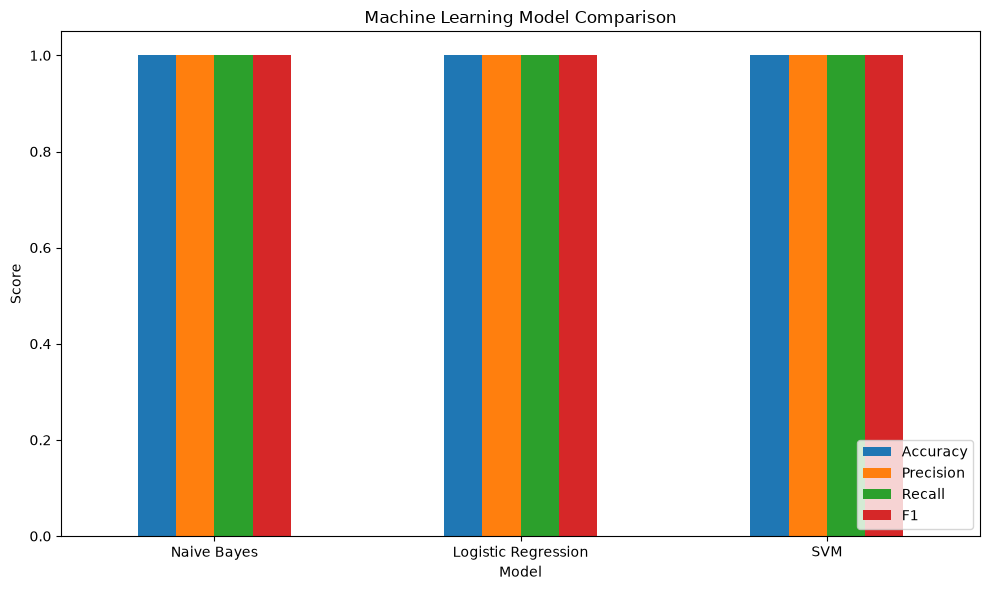

In [18]:
plot_df = results_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1"]]

ax = plot_df.plot(kind="bar", figsize=(10, 6))
ax.set_title("Machine Learning Model Comparison")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


### Model Selection

For scam detection, recall is important because missing a scam can be costly. Here we use F1-score as the default selection metric because it balances precision and recall.


In [19]:
best_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_name]

print("Selected best model:", best_name)
print("\nClassification report:")
print(classification_report(y_test, best_model.predict(X_test), digits=4))


Selected best model: Naive Bayes

Classification report:
              precision    recall  f1-score   support

        safe     1.0000    1.0000    1.0000        17
        scam     1.0000    1.0000    1.0000        14

    accuracy                         1.0000        31
   macro avg     1.0000    1.0000    1.0000        31
weighted avg     1.0000    1.0000    1.0000        31



## 10. Confusion Matrix

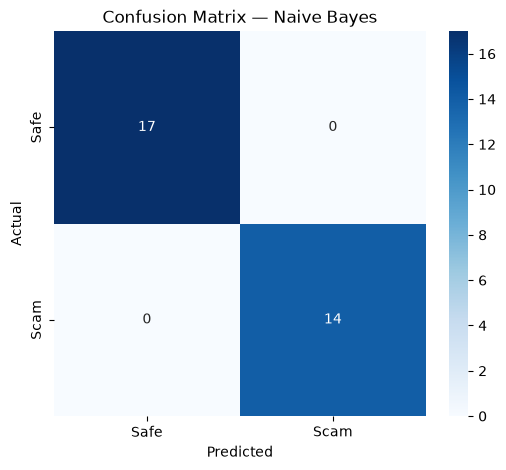

In [20]:
best_prediction = best_model.predict(X_test)
cm = confusion_matrix(y_test, best_prediction, labels=["safe", "scam"])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Safe", "Scam"],
    yticklabels=["Safe", "Scam"]
)
plt.title(f"Confusion Matrix — {best_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


## 11. Test the Model on New Messages

In [21]:
test_messages = [
    "URGENT! Your bank account will be blocked today. Send your OTP immediately.",
    "Your electricity bill is due next week. Please pay through the official portal.",
    "Congratulations! You won a cash prize. Pay a processing fee to claim it."
]

test_predictions = best_model.predict(test_messages)

for message, prediction in zip(test_messages, test_predictions):
    print(f"Message: {message}")
    print(f"Prediction: {prediction.upper()}")
    print("-" * 80)


Message: URGENT! Your bank account will be blocked today. Send your OTP immediately.
Prediction: SCAM
--------------------------------------------------------------------------------
Message: Your electricity bill is due next week. Please pay through the official portal.
Prediction: SAFE
--------------------------------------------------------------------------------
Message: Congratulations! You won a cash prize. Pay a processing fee to claim it.
Prediction: SCAM
--------------------------------------------------------------------------------


## 12. Save the Best Model

In [22]:
MODEL_DIR = os.path.join("..", "models")
os.makedirs(MODEL_DIR, exist_ok=True)

MODEL_PATH = os.path.join(MODEL_DIR, "scam_model.pkl")
RESULTS_PATH = os.path.join(MODEL_DIR, "model_results.csv")

joblib.dump(best_model, MODEL_PATH)
results_df.to_csv(RESULTS_PATH, index=False)

print("Model saved to:", MODEL_PATH)
print("Results saved to:", RESULTS_PATH)


Model saved to: ..\models\scam_model.pkl
Results saved to: ..\models\model_results.csv
